In [5]:
%load_ext autoreload
%autoreload 2

import numpy as np 
import functions 

from matplotlib import pyplot as plt


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [156]:
sigma = np.load("data/peyta_sigma.npy")
dsigma = np.load("data/peyta_dsigma.npy")
theta_cm = np.load("data/peyta_theta_cm.npy")
ke_cm = np.load("data/peyta_ke_cm.npy")

rounded_theta_cm = np.ceil( theta_cm / 5) * 5

print( np.unique( rounded_theta_cm ) )

[ 55.  60.  70.  75.  80.  90.  95. 105. 110. 120. 130. 135. 140. 145.
 160. 165.]


In [43]:
all_cs = functions.get_all_cs(rounded_theta_cm, ke_cm, sigma, dsigma)

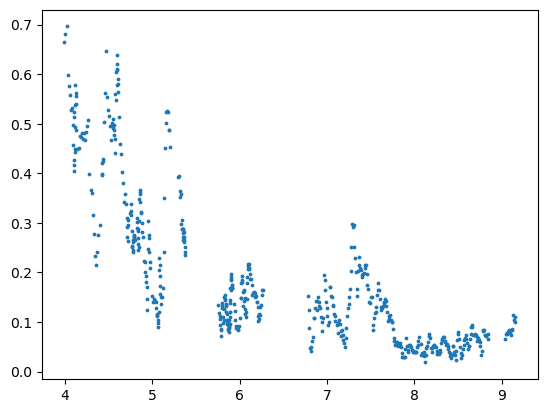

In [61]:
plt.scatter(all_cs["55.0"]["ke"], all_cs["55.0"]["sigma"], s=3)
plt.show()

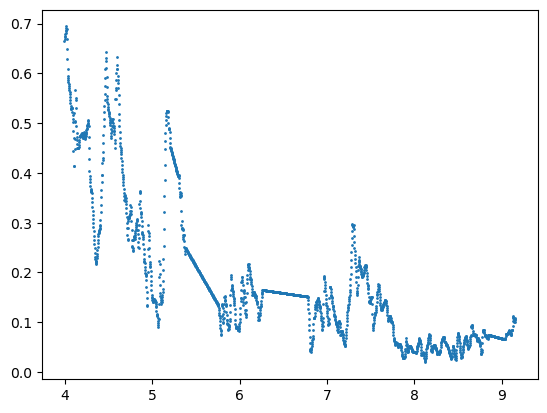

In [ ]:
# This is bad, it's interpolating the gaps too. 
# Only want to apply interpolation to the valid regions.

ke_55 = all_cs["55.0"]["ke"]
sigma_55 = all_cs["55.0"]["sigma"]

ke_55_uniform = np.linspace(
    ke_55.min(),
    ke_55.max(),
    2000
)

sigma_55_uniform = np.interp(
    ke_55_uniform, 
    ke_55,
    sigma_55
)


plt.scatter(ke_55_uniform, sigma_55_uniform, s=1)

In [103]:
print(np.max(np.diff(ke_55)))
print(np.min(np.diff(ke_55)))
print(np.unique(np.diff(np.round(ke_55, 3))))

0.5114296219762764
0.0
[0.    0.001 0.001 0.002 0.002 0.003 0.003 0.004 0.004 0.005 0.005 0.007
 0.008 0.008 0.008 0.009 0.009 0.009 0.01  0.011 0.012 0.012 0.013 0.013
 0.013 0.014 0.016 0.017 0.017 0.021 0.023 0.024 0.028 0.091 0.191 0.384
 0.511]


In [154]:
interp_55, ke_s, sigma_s = functions.get_interpolation(ke_55, sigma_55, gap_size = 0.1)

197


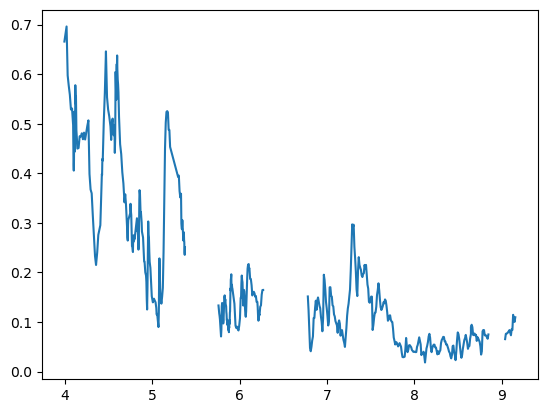

In [155]:
plt.plot(ke_s, sigma_s)

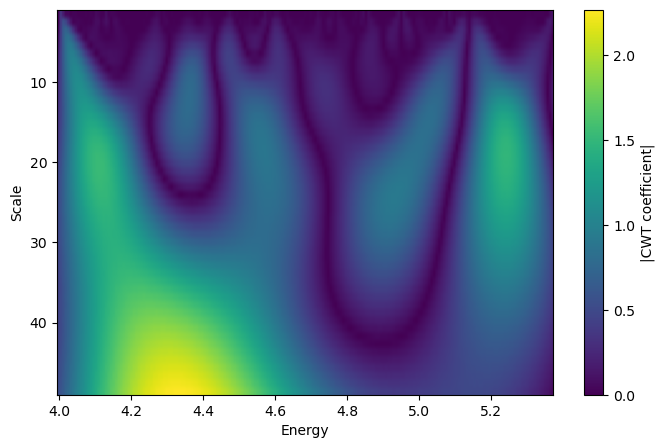

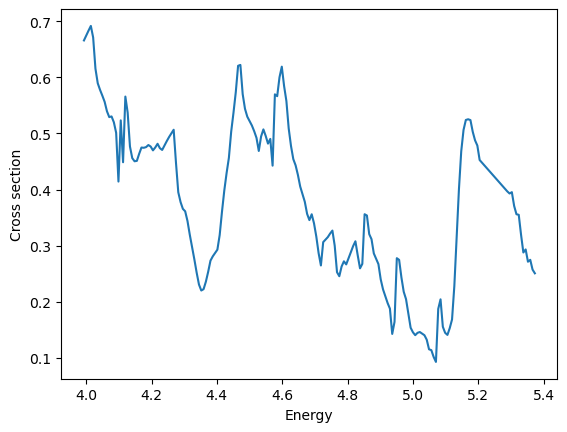

In [157]:
import pywt
import numpy as np

ke_part, sigma_part = interp_55[0]

scales = np.arange(1, 50)

coeffs, freqs = pywt.cwt(
    sigma_part,
    scales,
    "mexh"
)

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.imshow(
    np.abs(coeffs),
    extent=[
        ke_part[0],
        ke_part[-1],
        scales[-1],
        scales[0]
    ],
    aspect="auto"
)

plt.xlabel("Energy")
plt.ylabel("Scale")
plt.colorbar(label="|CWT coefficient|")
plt.show()

plt.plot(ke_part, sigma_part)
plt.xlabel("Energy")
plt.ylabel("Cross section")
plt.show()

In [207]:
peaks = functions.get_peaks(interp_55)

In [208]:
print(peaks)

[4.0212945  4.12693026 4.26073556 4.4649647  4.53538854 4.60581239
 4.71144815 4.75370245 4.81708391 4.8663806  4.97201636 5.08469451
 5.16920312 5.33117796 5.79817169 5.80269772 5.83437993 5.91132243
 5.97468684 6.02447316 6.02899919 6.10594169 6.25530066 6.78874615
 6.8899995  6.97437729 7.05875508 7.14313287 7.2950129  7.44689293
 7.59033517 7.64939963 7.83503077 7.93628412 8.02909969 8.05441303
 8.17254194 8.34129752 8.50161532 8.67880869 8.82225093 9.13073508
 9.13906359]


[  4  19  38  67  77  87 102 108 117 124 139 155 167 190]
[  9  10  17  34  48  59  60  77 110]
[  1  13  23  33  43  61  79  96 103 125 137 148 151 165 185 204 225 242]
[11 12]


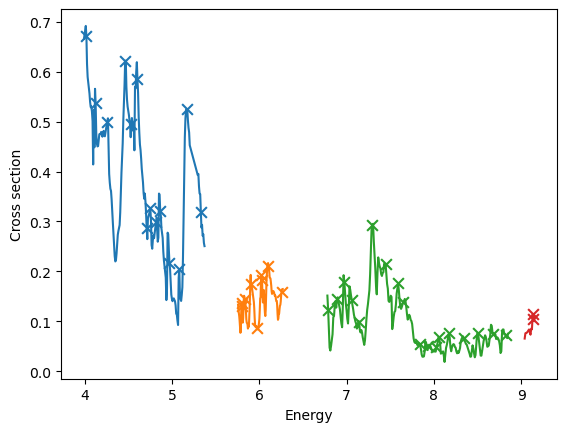

In [ ]:
from scipy.signal import find_peaks_cwt

widths = np.arange(1, 50)

for ke_part, sigma_part in interp_55:

    peak_idx = find_peaks_cwt(
        sigma_part,
        np.arange(1, 50),
        min_length=3,
        min_snr=1
)
    print(peak_idx)

    plt.plot(ke_part, sigma_part)

    plt.scatter(
        ke_part[peak_idx],
        sigma_part[peak_idx],
        marker="x",
        s=60
    )

plt.xlabel("Energy")
plt.ylabel("Cross section")
plt.show()

In [216]:
all_cs = functions.get_all_cs(rounded_theta_cm, ke_cm, sigma, dsigma)

all_peaks = functions.get_all_peaks(all_cs)

for angle in all_peaks.keys():
    print(all_peaks[f"{angle}"])

55.0
60.0
70.0
75.0
80.0
90.0
95.0
105.0
110.0
120.0
130.0
135.0
140.0
145.0
160.0
165.0
[4.0212945  4.12693026 4.26073556 4.4649647  4.53538854 4.60581239
 4.71144815 4.75370245 4.81708391 4.8663806  4.97201636 5.08469451
 5.16920312 5.33117796 5.79817169 5.80269772 5.83437993 5.91132243
 5.97468684 6.02447316 6.02899919 6.10594169 6.25530066 6.78874615
 6.8899995  6.97437729 7.05875508 7.14313287 7.2950129  7.44689293
 7.59033517 7.64939963 7.83503077 7.93628412 8.02909969 8.05441303
 8.17254194 8.34129752 8.50161532 8.67880869 8.82225093 9.13073508
 9.13906359]
[4.03213289 4.12965269 4.23692448 4.35394825 4.44171607 4.56849182
 4.59774776 4.86857104 4.96157179 5.06785836 5.16085911 5.77101551
 5.80722375 5.8298539  5.92037448 6.01089507 6.01089507 6.09688963
 6.25530066 6.7888156  6.88239508 6.90791676 6.97597457 7.29074193
 7.43536477 7.44387199 7.56297316 7.68207432 7.9372911  8.14997174
 8.2010151  8.6263764  8.71144866 8.81353537]
[4.0118252  4.205061   4.21752783 4.41076363 4.5

55.0


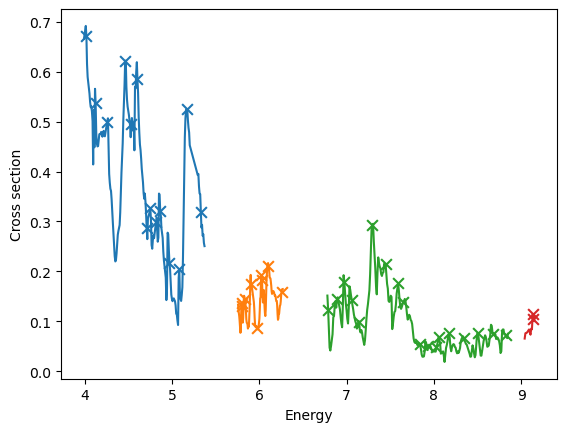

60.0


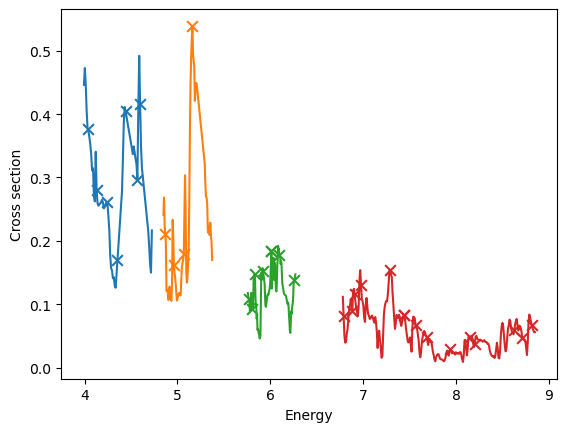

70.0


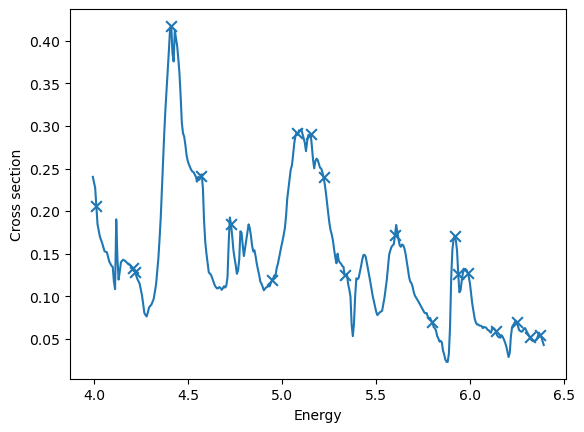

75.0


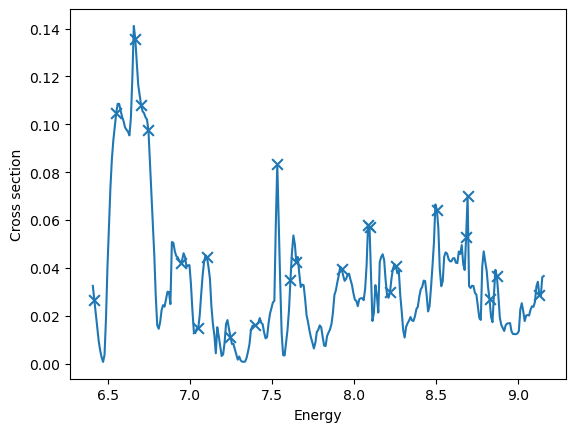

80.0


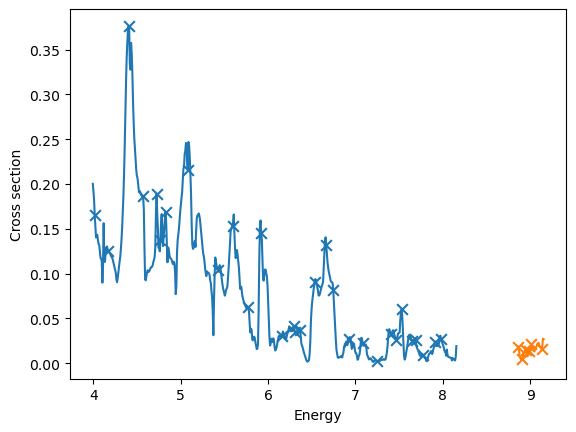

90.0


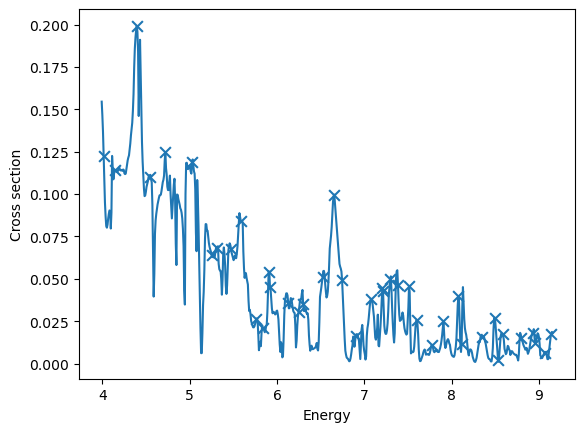

95.0


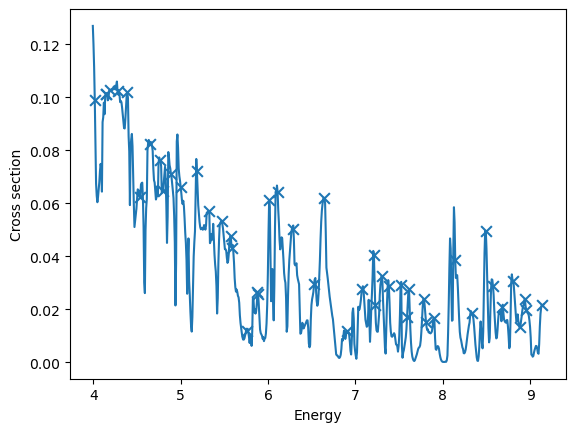

105.0


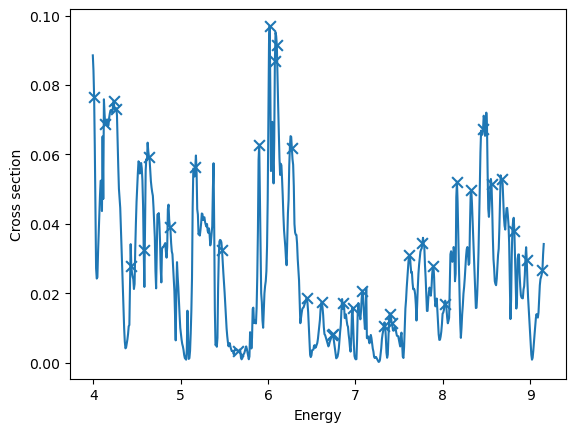

110.0


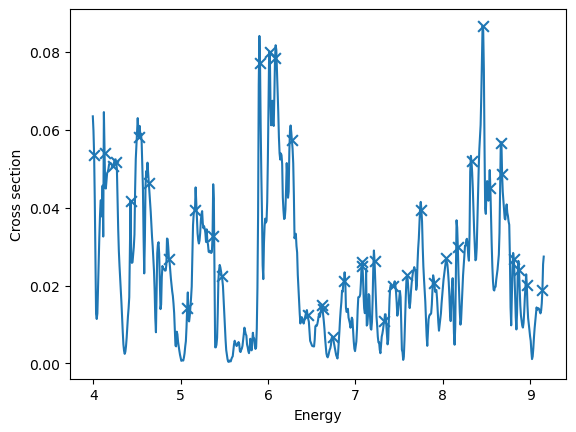

120.0


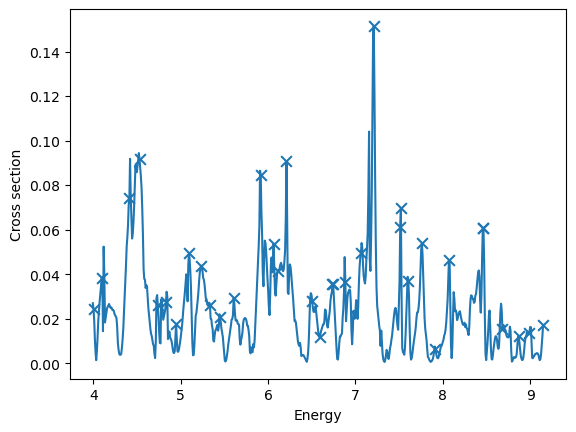

130.0


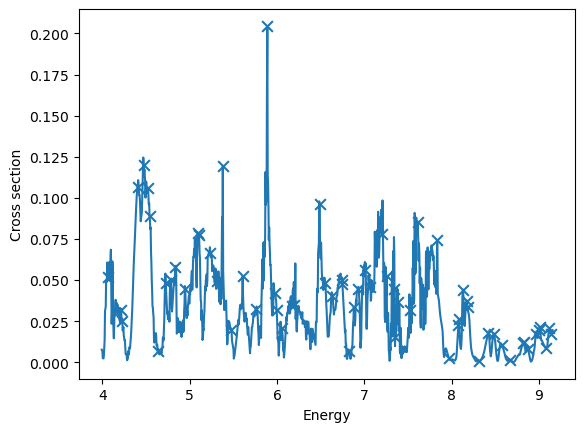

135.0


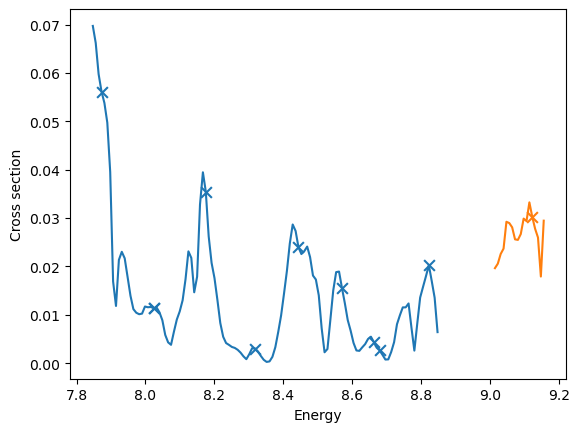

140.0


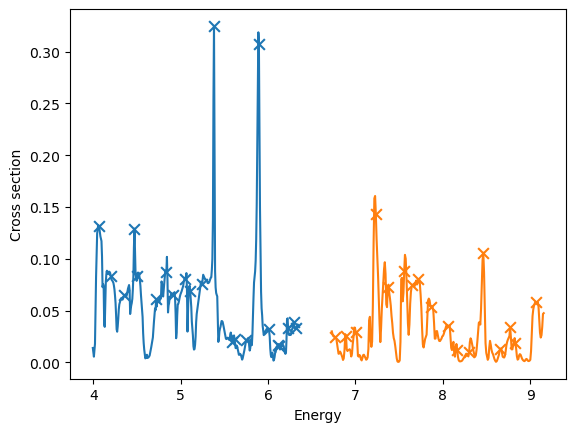

145.0


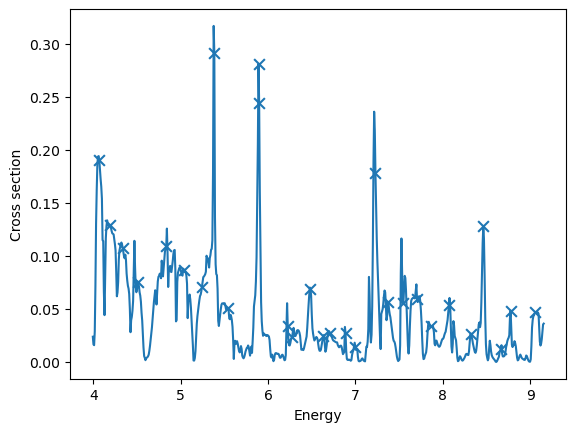

160.0


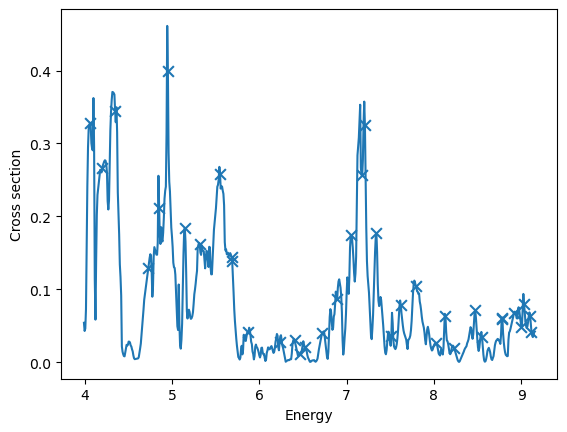

165.0


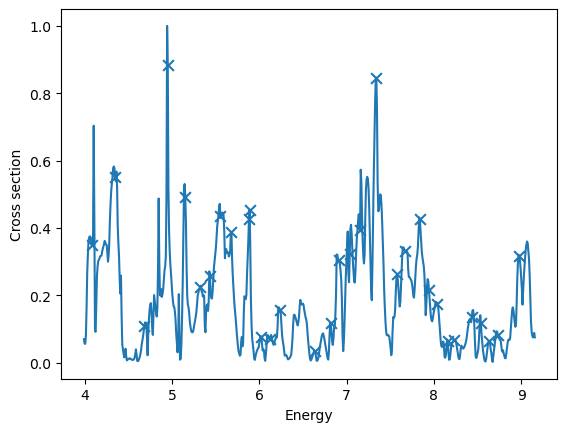

In [217]:
functions.visualise_all_peaks(all_cs)

In [1]:
plt.scatter(
    all_cs["80.0"]["ke"],
    all_cs["80.0"]["sigma"],
    s=1
)

plt.show()



NameError: name 'plt' is not defined

In [ ]:
plt.scatter(
    all_cs["135.0"]["ke"],
    all_cs["135.0"]["sigma"]
)

plt.show()